# 01: Exploratory Data Analysis

**Business question:** *Why do customers leave bad reviews, and can we predict and prevent late deliveries?*

**Population:** delivered orders only (96,470); trends use 2017-01 to 2018-08 (see `docs/DATA_QUALITY_REPORT.md`).
Extracts come from `sql/05_eda_queries.sql`; tests and effect sizes come from `src/stats.py`.

## Five insights (every number is produced by the cells below)

1. **Late delivery roughly halves the review score.** Late orders average **2.27★ vs 4.29★** on time (median 1★ vs 5★). Mann-Whitney U: p < 1e-300, **rank-biserial r = -0.64** (large effect). Mean gap **-2.02★, 95% bootstrap CI [-2.06, -1.98]**. 1-2★ reviews: 62.4% of late orders vs 9.3% on time (Cramér's V = 0.40).
2. **It isn't a geography effect, and lateness has a dose-response pattern.** In **all 21 states** with ≥30 late reviewed orders, late orders score 1.63 to 2.62★ lower than on-time ones. Among late orders, the later the parcel, the lower the score (Spearman ρ = -0.40).
3. **Lateness comes in spikes, not a steady rate, and the estimates drift.** The late rate is about 3% in normal months but **12.40% in Nov 2017** and **14.13% / 18.96% in Feb / Mar 2018**. Mar 2018 had almost the same volume as Jan 2018 (7,003 vs 7,069 orders) but more than three times the late rate (5.70%). Average promised time also fell from 24-28 days to **15.8 days by Aug 2018**. Implication for ML: use a **time-based split** and expect drift.
4. **Delivery estimates are heavily padded.** The median order arrives **12.4 days before** its estimated date, and 59.9% arrive in under half the promised time. Late orders are the exceptions in a system that normally over-delivers (a likely reason they stand out so sharply to customers).
5. **Payment method affects approval time, not shipping.** Boleto orders wait a median **29.06 h** for approval vs **0.27 h** for cards (Kruskal-Wallis ε² = 0.34, large). Once approved, boleto and card orders take the same time to arrive (mean **12.12 vs 12.17 days**). Method vs lateness is statistically significant but **negligible** (Cramér's V = 0.013).

*Bonus for Module 2:* customers with a late order leave a written comment more often (58.9% vs 39.3%), so complaint text is concentrated where the problems are.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.db import connect, load_named_sql
from src.stats import bootstrap_diff_ci, chi_square, kruskal, mann_whitney, spearman

pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.4g}")

BLUE, ORANGE, MUTED, INK, INK2 = "#2a78d6", "#eb6834", "#c3c2b7", "#0b0b0b", "#52514e"
plt.rcParams.update(
    {
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.edgecolor": MUTED,
        "axes.labelcolor": INK2,
        "xtick.color": INK2,
        "ytick.color": INK2,
        "axes.grid": True,
        "grid.color": "#e6e5e0",
        "grid.linewidth": 0.6,
        "axes.axisbelow": True,
        "font.size": 10,
        "legend.frameon": False,
    }
)
FIG_DIR = ROOT / "docs" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)


def fmt_p(p):
    return "p < 1e-300" if p == 0 else f"p = {p:.3g}"


Q = {q.name: q.sql for q in load_named_sql("05_eda_queries.sql")}
with connect(read_only=True) as con:
    orders = con.execute(Q["eda_delivered_orders"]).df()
    monthly = con.execute(Q["eda_monthly_delivery"]).df()
reviewed = orders.dropna(subset=["review_score"]).copy()
print(f"delivered orders: {len(orders):,} | with a review: {len(reviewed):,}")

delivered orders: 96,470 | with a review: 95,824


## 0. What do review scores look like?

Scores are **ordinal** (1-5) and **J-shaped** (mostly 5★, then a bump at 1★). That's why the tests below are rank-based (Mann-Whitney, Spearman) rather than a t-test, which assumes roughly normal data.

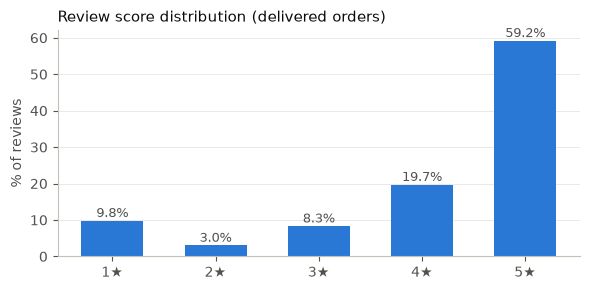

review_score
1    9.8
2      3
3    8.3
4   19.7
5   59.2
Name: proportion, dtype: Float64

In [2]:
dist = reviewed["review_score"].value_counts(normalize=True).sort_index().mul(100).round(1)
fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(dist.index, dist.values, color=BLUE, width=0.6)
for x, v in dist.items():
    ax.text(x, v + 1, f"{v}%", ha="center", fontsize=9, color=INK2)
ax.set_xticks(dist.index, [f"{i}★" for i in dist.index])
ax.set_ylabel("% of reviews")
ax.grid(axis="x", visible=False)
ax.set_title("Review score distribution (delivered orders)", loc="left", color=INK, fontsize=11)
plt.tight_layout()
plt.show()
dist

## Insight 1: Late delivery and review scores (the statistical test)

- **H0:** late and on-time orders have the same distribution of review scores. **H1:** they differ.
- **Test:** Mann-Whitney U (two-sided). **Effect size:** rank-biserial r (−1 to +1). **Uncertainty:** 95% bootstrap CI for the mean difference (2,000 resamples, seed 42).
- **Second view:** chi-square on late × (1-2★), with Cramér's V.

In [3]:
late = reviewed.loc[reviewed["is_late"], "review_score"]
on_time = reviewed.loc[~reviewed["is_late"], "review_score"]

mw = mann_whitney(late, on_time)
boot = bootstrap_diff_ci(late, on_time)
chi = chi_square(pd.crosstab(reviewed["is_late"], reviewed["review_score"] <= 2))

print(f"late:    n={mw['n_a']:,}  mean={mw['mean_a']:.2f}  median={mw['median_a']:.0f}")
print(f"on time: n={mw['n_b']:,}  mean={mw['mean_b']:.2f}  median={mw['median_b']:.0f}")
print(
    f"Mann-Whitney U={mw['u_statistic']:,.0f}, {fmt_p(mw['p_value'])}, "
    f"rank-biserial r={mw['rank_biserial']:.2f}"
)
print(
    f"mean difference {boot['diff']:.2f} stars, "
    f"95% CI [{boot['ci_low']:.2f}, {boot['ci_high']:.2f}]"
)
print(
    f"chi-square late x (1-2 stars): chi2={chi['chi2']:,.0f}, {fmt_p(chi['p_value'])}, "
    f"Cramer's V={chi['cramers_v']:.2f}"
)
share = reviewed.groupby("is_late")["review_score"].apply(lambda s: (s <= 2).mean() * 100).round(1)
print(f"1-2 star share: late {share[True]}% vs on time {share[False]}%")

late:    n=6,381  mean=2.27  median=1
on time: n=89,443  mean=4.29  median=5
Mann-Whitney U=103,305,546, p < 1e-300, rank-biserial r=-0.64
mean difference -2.02 stars, 95% CI [-2.06, -1.98]
chi-square late x (1-2 stars): chi2=15,064, p < 1e-300, Cramer's V=0.40
1-2 star share: late 62.4% vs on time 9.3%


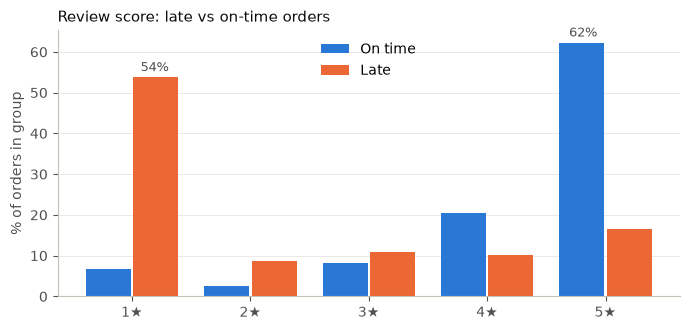

In [4]:
pct = (
    reviewed.groupby("is_late")["review_score"]
    .value_counts(normalize=True)
    .mul(100)
    .unstack(0)
    .rename(columns={False: "On time", True: "Late"})
)
x = np.arange(1, 6)
w = 0.38
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.bar(x - w / 2 - 0.01, pct["On time"], w, color=BLUE, label="On time")
ax.bar(x + w / 2 + 0.01, pct["Late"], w, color=ORANGE, label="Late")
ax.text(
    5 - w / 2,
    pct.loc[5, "On time"] + 1.5,
    f"{pct.loc[5, 'On time']:.0f}%",
    ha="center",
    fontsize=9,
    color=INK2,
)
ax.text(
    1 + w / 2,
    pct.loc[1, "Late"] + 1.5,
    f"{pct.loc[1, 'Late']:.0f}%",
    ha="center",
    fontsize=9,
    color=INK2,
)
ax.set_xticks(x, [f"{i}★" for i in x])
ax.set_ylabel("% of orders in group")
ax.grid(axis="x", visible=False)
ax.legend(loc="upper center")
ax.set_title("Review score: late vs on-time orders", loc="left", color=INK, fontsize=11)
plt.tight_layout()
fig.savefig(FIG_DIR / "eda_reviews_late_vs_on_time.png", dpi=150)
plt.show()

**Reading it:** p tells us the difference isn't chance. r = -0.64 tells us it's **large**: pick a random late order and a random on-time order, and the late one has the lower score far more often than the higher one. The CI is narrow because n is large; the gap is about 2 stars.

## Insight 2: Is it really lateness, or just geography? (confounder check + dose-response)

Late orders are concentrated in certain states (Day 1, q04). If those states also simply review lower, the gap could be partly geography. So compare late vs on-time **within each state**.

states with >=30 late reviewed orders: 21; late scores lower in 21 of them; gap range 1.63 to 2.62 stars


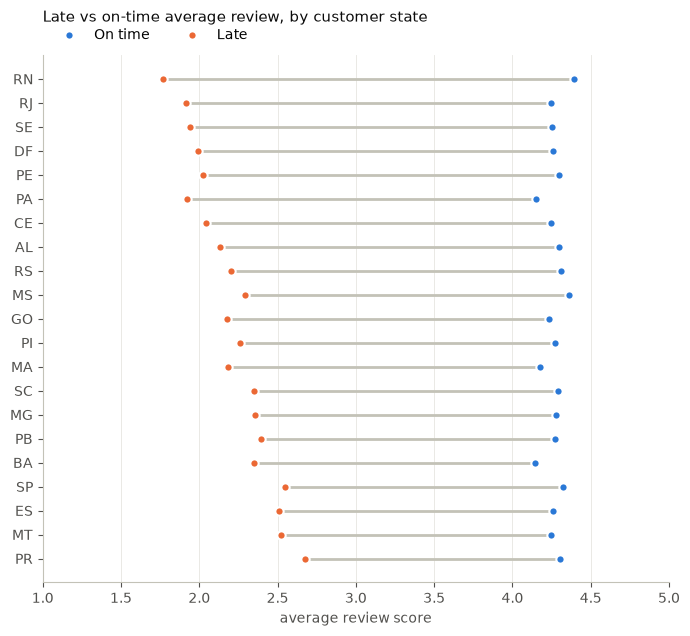

,on_time_avg,late_avg,n_on_time,n_late,gap
customer_state,,,,,
PR,4.3,2.68,4704,194,1.63
MT,4.25,2.52,827,52,1.73
ES,4.26,2.51,1765,205,1.75
SP,4.32,2.55,38485,1786,1.78
BA,4.14,2.35,2844,384,1.79
PB,4.27,2.39,459,51,1.88
MG,4.28,2.36,10776,506,1.92
SC,4.29,2.35,3236,284,1.94
MA,4.18,2.18,593,122,2


In [5]:
by_state = (
    reviewed.groupby(["customer_state", "is_late"])["review_score"]
    .agg(["mean", "size"])
    .unstack("is_late")
)
by_state.columns = ["on_time_avg", "late_avg", "n_on_time", "n_late"]
by_state = by_state[by_state["n_late"] >= 30].copy()
by_state["gap"] = by_state["on_time_avg"] - by_state["late_avg"]
by_state = by_state.sort_values("gap")
print(
    f"states with >=30 late reviewed orders: {len(by_state)}; "
    f"late scores lower in {(by_state['gap'] > 0).sum()} of them; "
    f"gap range {by_state['gap'].min():.2f} to {by_state['gap'].max():.2f} stars"
)

fig, ax = plt.subplots(figsize=(7, 0.26 * len(by_state) + 1))
y = np.arange(len(by_state))
ax.hlines(y, by_state["late_avg"], by_state["on_time_avg"], color=MUTED, linewidth=2)
ax.scatter(
    by_state["on_time_avg"],
    y,
    color=BLUE,
    s=36,
    label="On time",
    zorder=3,
    edgecolor="white",
    linewidth=1.5,
)
ax.scatter(
    by_state["late_avg"],
    y,
    color=ORANGE,
    s=36,
    label="Late",
    zorder=3,
    edgecolor="white",
    linewidth=1.5,
)
ax.set_yticks(y, by_state.index)
ax.set_xlim(1, 5)
ax.set_xlabel("average review score")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2)
ax.set_title(
    "Late vs on-time average review, by customer state", loc="left", color=INK, fontsize=11, pad=24
)
plt.tight_layout()
fig.savefig(FIG_DIR / "eda_gap_by_state.png", dpi=150)
plt.show()
by_state.round(2)

Spearman delay vs score, all delivered: rho=-0.18 (p < 1e-300)
Spearman delay vs score, late orders only: rho=-0.40 (p = 1.21e-246)


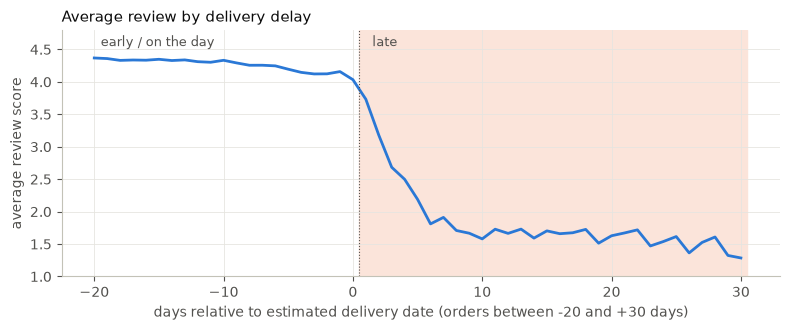

In [6]:
# Dose-response: average review by days late/early.
# Window -20..+30 days: outside it, the number of orders per day gets small.
curve = (
    reviewed[reviewed["delay_days"].between(-20, 30)]
    .groupby("delay_days")["review_score"]
    .agg(["mean", "size"])
)
sp_all = spearman(reviewed["delay_days"], reviewed["review_score"])
sp_late = spearman(reviewed.loc[reviewed["is_late"], "delay_days"], late)
print(
    f"Spearman delay vs score, all delivered: rho={sp_all['rho']:.2f} ({fmt_p(sp_all['p_value'])})"
)
print(
    f"Spearman delay vs score, late orders only: "
    f"rho={sp_late['rho']:.2f} ({fmt_p(sp_late['p_value'])})"
)

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.axvspan(0.5, 30.5, color="#fbe4da", zorder=0)
ax.plot(curve.index, curve["mean"], color=BLUE, linewidth=2)
ax.axvline(0.5, color=INK2, linewidth=0.8, linestyle=":")
ax.text(1.5, 4.55, "late", color=INK2, fontsize=9)
ax.text(-19.5, 4.55, "early / on the day", color=INK2, fontsize=9)
ax.set_xlabel("days relative to estimated delivery date (orders between -20 and +30 days)")
ax.set_ylabel("average review score")
ax.set_ylim(1, 4.8)
ax.set_title("Average review by delivery delay", loc="left", color=INK, fontsize=11)
plt.tight_layout()
fig.savefig(FIG_DIR / "eda_review_by_delay.png", dpi=150)
plt.show()

**Reading it:** the gap appears in every state checked, so geography doesn't explain it away. The curve is flat while orders are early, drops sharply as soon as an order is late, then levels off near the floor. Customers react to *crossing* the promise more than to the exact number of days early. This is still observational evidence, not a controlled experiment. Module 2 adds a second line of evidence by checking whether low-score reviews *mention* delivery in their text.

## Insight 3: When is delivery late? (seasonality and drift)

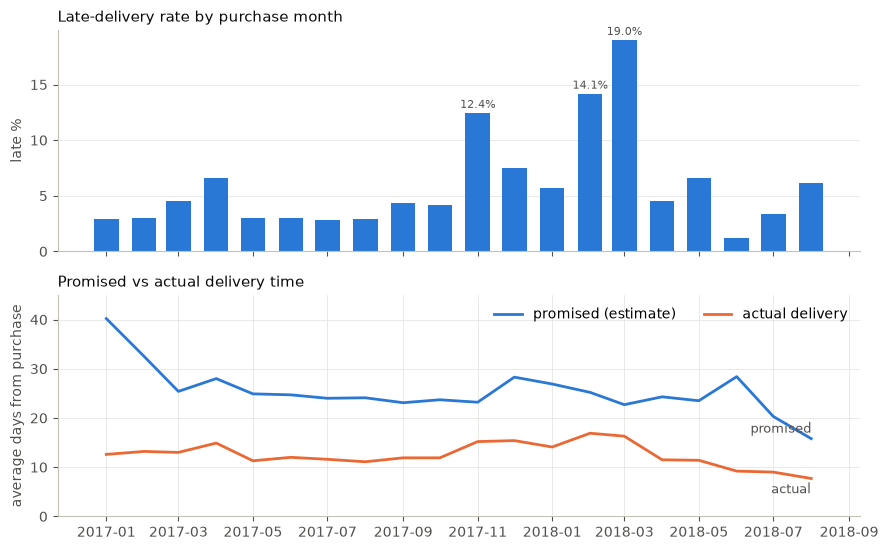

,year_month,delivered_orders,late_pct,avg_promised_days,avg_delivery_days
0,2017-01,750,2.93,40.2,12.6
1,2017-02,1653,2.96,32.5,13.2
2,2017-03,2546,4.56,25.4,13
3,2017-04,2303,6.56,28,14.9
4,2017-05,3545,2.99,24.9,11.3
5,2017-06,3135,3.03,24.7,12
6,2017-07,3872,2.79,24,11.6
7,2017-08,4193,2.91,24.1,11.1
8,2017-09,4150,4.39,23.1,11.9
9,2017-10,4478,4.18,23.7,11.9


In [7]:
m = monthly.copy()
m["month"] = pd.to_datetime(m["year_month"])
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 5.6), sharex=True)
ax1.bar(m["month"], m["late_pct"], width=20, color=BLUE)
ax1.set_ylabel("late %")
ax1.grid(axis="x", visible=False)
ax1.set_title("Late-delivery rate by purchase month", loc="left", color=INK, fontsize=11)
for _, r in m[m["late_pct"] > 10].iterrows():
    ax1.text(
        r["month"],
        r["late_pct"] + 0.5,
        f"{r['late_pct']:.1f}%",
        ha="center",
        fontsize=8,
        color=INK2,
    )
ax2.plot(m["month"], m["avg_promised_days"], color=BLUE, linewidth=2, label="promised (estimate)")
ax2.plot(m["month"], m["avg_delivery_days"], color=ORANGE, linewidth=2, label="actual delivery")
ax2.text(
    m["month"].iloc[-1],
    m["avg_promised_days"].iloc[-1] + 1.2,
    "promised",
    color=INK2,
    fontsize=9,
    ha="right",
)
ax2.text(
    m["month"].iloc[-1],
    m["avg_delivery_days"].iloc[-1] - 3,
    "actual",
    color=INK2,
    fontsize=9,
    ha="right",
)
ax2.set_ylabel("average days from purchase")
ax2.set_ylim(0, 45)
ax2.legend(loc="upper right", ncol=2)
ax2.set_title("Promised vs actual delivery time", loc="left", color=INK, fontsize=11)
plt.tight_layout()
fig.savefig(FIG_DIR / "eda_monthly_late_and_promise.png", dpi=150)
plt.show()
monthly

**Reading it:** late deliveries cluster in **Nov-Dec 2017** (the Black Friday and Christmas peak) and **Feb-Mar 2018**. Feb-Mar 2018 can't be explained by volume alone, because January had similar volume with a much lower late rate. Promised times also shrink through 2018 while actual times fall too. For the model this means (a) a **time-based split**, (b) a test period whose late rate may differ from training, and (c) promised days are a key feature whose meaning changes over time.

## Insight 4: How padded are the delivery estimates?

median buffer: 12.4 days early; mean 11.8
delivered in under half the promised time: 59.9%
late (date-based): 6.77%


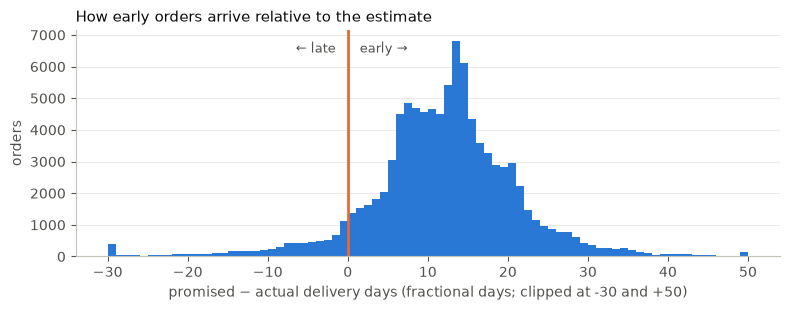

In [8]:
buffer = orders["promised_days"] - orders["delivery_days"]
print(f"median buffer: {buffer.median():.1f} days early; mean {buffer.mean():.1f}")
print(
    "delivered in under half the promised time: "
    f"{(orders['delivery_days'] <= orders['promised_days'] / 2).mean() * 100:.1f}%"
)
print(f"late (date-based): {orders['is_late'].mean() * 100:.2f}%")

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(buffer.clip(-30, 50), bins=80, color=BLUE)
ax.axvline(0, color=ORANGE, linewidth=2)
ax.text(-1.5, ax.get_ylim()[1] * 0.9, "← late", color=INK2, fontsize=9, ha="right")
ax.text(1.5, ax.get_ylim()[1] * 0.9, "early →", color=INK2, fontsize=9, ha="left")
ax.set_xlabel("promised − actual delivery days (fractional days; clipped at -30 and +50)")
ax.set_ylabel("orders")
ax.grid(axis="x", visible=False)
ax.set_title("How early orders arrive relative to the estimate", loc="left", color=INK, fontsize=11)
plt.tight_layout()
fig.savefig(FIG_DIR / "eda_estimate_buffer.png", dpi=150)
plt.show()

*Note: this chart uses fractional days, so it differs slightly from the official date-based late flag.*

**Reading it:** most orders arrive well before the estimate, so estimates are conservative. That creates a trade-off: tighter, more accurate estimates would make the site more attractive but would turn more orders "late" in the customer's eyes. That's a decision for the business, and the model on Day 3 can help by flagging the orders whose estimate is genuinely at risk.

## Insight 5: Payment method vs approval time and delivery time

Payment **method** only (no instalment analysis, by project scope). Approval time is measured *after* purchase, so it's used here for analysis, **not** as an ML feature; payment method itself is known at purchase.

In [9]:
pay = orders[
    orders["payment_type_main"].isin(["credit_card", "boleto", "voucher", "debit_card"])
].copy()
pay["after_approval_days"] = pay["delivery_days"] - pay["approval_hours"] / 24
summary = (
    pay.groupby("payment_type_main")
    .agg(
        orders=("order_id", "size"),
        median_approval_h=("approval_hours", "median"),
        pct_approval_over_24h=("approval_hours", lambda s: (s > 24).mean() * 100),
        mean_delivery_days=("delivery_days", "mean"),
        mean_days_after_approval=("after_approval_days", "mean"),
        late_pct=("is_late", lambda s: s.mean() * 100),
    )
    .sort_values("orders", ascending=False)
)
kw = kruskal({k: g["approval_hours"].dropna() for k, g in pay.groupby("payment_type_main")})
chi_pay = chi_square(pd.crosstab(pay["payment_type_main"], pay["is_late"]))
print(
    f"approval time across methods: Kruskal-Wallis H={kw['h_statistic']:,.0f}, "
    f"{fmt_p(kw['p_value'])}, epsilon^2={kw['epsilon_squared']:.2f}"
)
print(
    f"late x method: chi2={chi_pay['chi2']:.1f}, {fmt_p(chi_pay['p_value'])}, "
    f"Cramer's V={chi_pay['cramers_v']:.3f}"
)
summary.round(2)

approval time across methods: Kruskal-Wallis H=32,338, p < 1e-300, epsilon^2=0.34
late x method: chi2=17.4, p = 0.000586, Cramer's V=0.013


,orders,median_approval_h,pct_approval_over_24h,mean_delivery_days,mean_days_after_approval,late_pct
payment_type_main,,,,,,
credit_card,72818,0.27,7.33,12.35,12.17,6.69
boleto,19191,29.06,57.17,13.49,12.12,7.32
voucher,2977,0.28,13.1,12.51,12.19,6.05
debit_card,1483,0.84,10.05,10.79,10.41,5.33


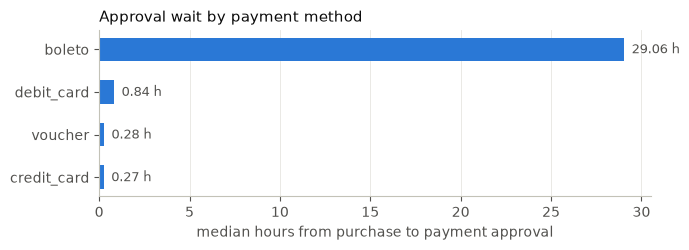

In [10]:
s = summary.sort_values("median_approval_h")
fig, ax = plt.subplots(figsize=(7, 2.6))
ax.barh(s.index, s["median_approval_h"], color=BLUE, height=0.55)
for yy, v in enumerate(s["median_approval_h"]):
    ax.text(v + 0.4, yy, f"{v:.2f} h", va="center", fontsize=9, color=INK2)
ax.set_xlabel("median hours from purchase to payment approval")
ax.grid(axis="y", visible=False)
ax.set_title("Approval wait by payment method", loc="left", color=INK, fontsize=11)
plt.tight_layout()
fig.savefig(FIG_DIR / "eda_approval_by_payment.png", dpi=150)
plt.show()

**Reading it:** boleto is a bank slip the customer pays separately, so the order waits for the payment to clear. That wait (median 29 h) is a **large** effect across methods. Once the clock starts at approval, boleto orders arrive just as fast as card orders. The link between method and *lateness* is statistically significant (large n) but **negligible in size** (Cramér's V ≈ 0.01). Significant doesn't mean important. For the model, payment method stays a candidate feature, but we shouldn't expect it to carry much signal.

## Bonus (for Module 2): who writes comments?

In [11]:
rate = reviewed.groupby("is_late")["has_comment"].mean().mul(100).round(1)
print(f"written comment: late orders {rate[True]}% vs on-time {rate[False]}%")
print(
    "average score with comment "
    f"{reviewed.loc[reviewed['has_comment'], 'review_score'].mean():.2f} "
    f"vs without {reviewed.loc[~reviewed['has_comment'], 'review_score'].mean():.2f}"
)

written comment: late orders 58.9% vs on-time 39.3%
average score with comment 3.77 vs without 4.42


## What this means for the next steps

| Finding | Consequence |
|---|---|
| Late delivery is strongly and robustly linked to bad reviews | Predicting lateness at purchase time is worth doing (Day 3) |
| Late rate spikes and drifts over time | Time-based train/validation/test split; check the test-period late rate |
| Estimates are padded and change over time | `promised_days` is a key feature; interpret SHAP for it carefully |
| Payment method barely relates to lateness | Keep as a candidate feature; expect low importance |
| Unhappy customers write more | Module 2 has rich complaint text where it matters most |